# Assignment 3 · Federated Learning and Differential Privacy

Run the cells in order with the course ZIP in the notebook's working directory. The notebook uses NumPy, Matplotlib, PyTorch, and Ray Core. Install Ray in this kernel with `%pip install ray` if needed.

## 1. Dataset and client splits

Clients: 100 | Client 0 images: (344, 28, 28) | Label: 40


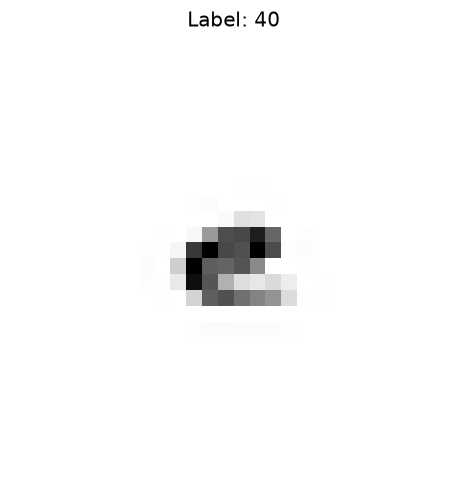

In [1]:
from copy import deepcopy
from pathlib import Path
from zipfile import ZipFile

import json
import platform
import time

import numpy as np
import matplotlib.pyplot as plt

DATA_ARCHIVE = Path("Assignment3-data.zip")
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

with ZipFile(DATA_ARCHIVE) as archive:
    with archive.open("Assignment3-data/train_data.npy") as file:
        train_data = np.load(file, allow_pickle=True)

client = train_data[0]
images = np.asarray(client["images"])
labels = np.asarray(client["labels"])

i = 0
print(f"Clients: {len(train_data)} | Client 0 images: {images.shape} | Label: {labels[i]}")
plt.imshow(images[i], cmap="gray")
plt.title(f"Label: {labels[i]}")
plt.axis("off")
plt.savefig(FIGURE_DIR / "sample.png", dpi=180)
plt.show()

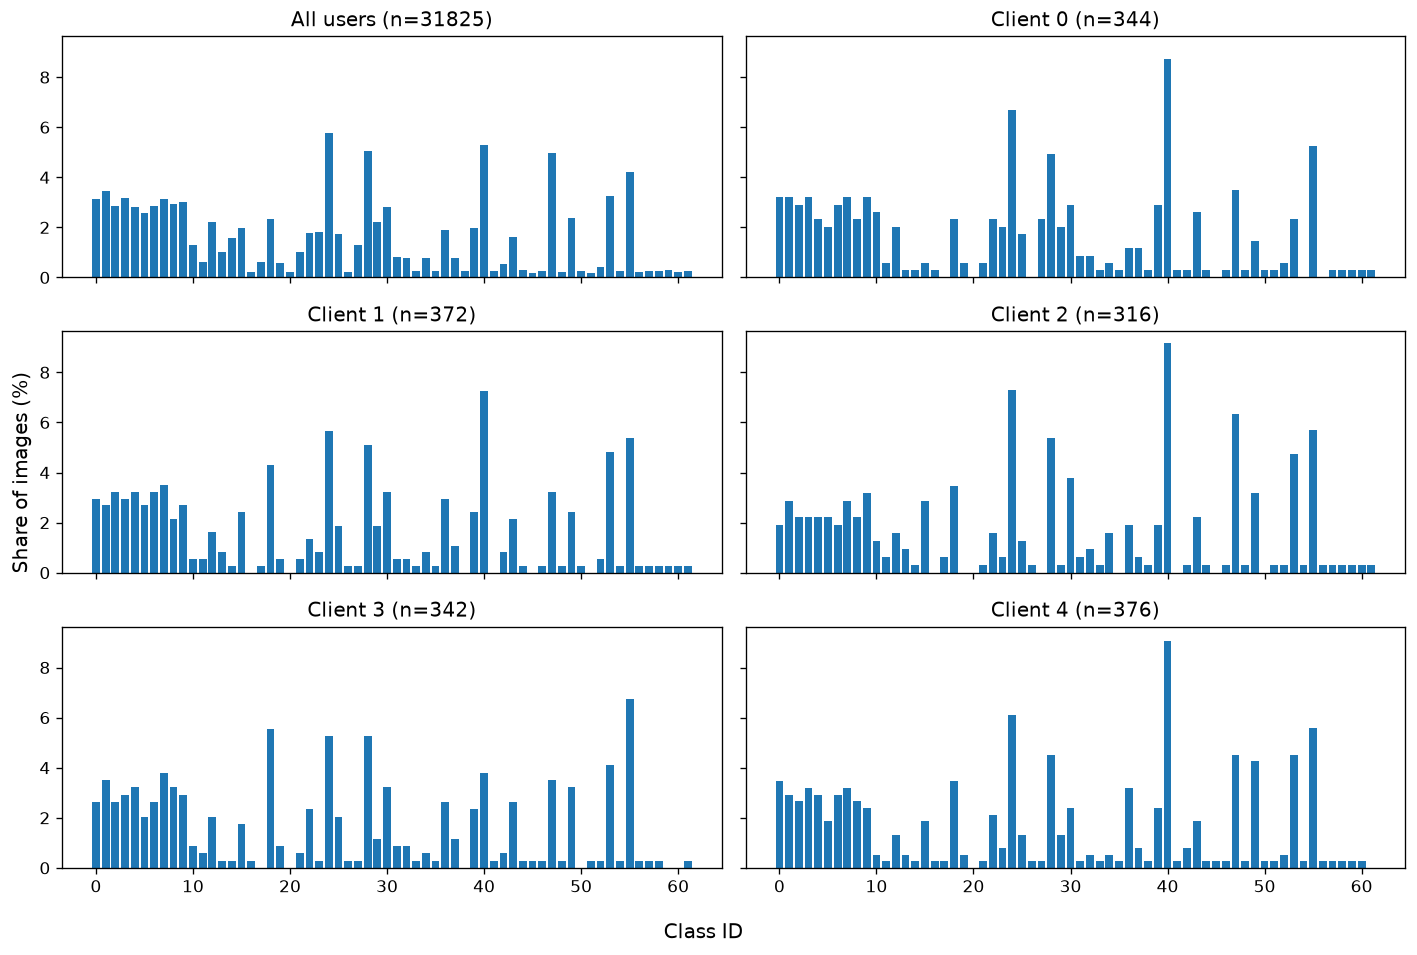

In [2]:
client_counts = np.stack([
    np.bincount(client["labels"], minlength=62)
    for client in train_data
])
overall_counts = client_counts.sum(axis=0)

fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, sharey=True)
panels = [("All users", overall_counts)]
panels += [(f"Client {i}", client_counts[i]) for i in range(5)]

for ax, (title, counts) in zip(axes.flat, panels):
    ax.bar(range(62), 100 * counts / counts.sum())
    ax.set_title(f"{title} (n={counts.sum()})")

fig.supxlabel("Class ID")
fig.supylabel("Share of images (%)")
fig.tight_layout()
plt.savefig(FIGURE_DIR / "class_distribution.png", dpi=180)
plt.show()

In [3]:
rng = np.random.default_rng(42)
client_splits = []

for client in train_data:
    x = np.asarray(client["images"])
    y = np.asarray(client["labels"])
    order = rng.permutation(len(y))
    if len(y) < 2:
        raise ValueError("Each client needs at least two samples for an 80/20 split")
    cut = int(0.8 * len(y))

    train_idx, val_idx = order[:cut], order[cut:]
    client_splits.append({
        "train_indices": train_idx,
        "val_indices": val_idx,
        "train": (x[train_idx], y[train_idx]),
        "val": (x[val_idx], y[val_idx]),
    })

x_train, y_train = client_splits[0]["train"]
x_val, y_val = client_splits[0]["val"]
print(f"Client 0 split: {len(y_train)} training images, {len(y_val)} validation images")

Client 0 split: 275 training images, 69 validation images


## 2. Model and local training

Each image is flattened before the 128-unit ReLU layer. Cross-entropy takes the 62 output scores directly.

In [4]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")


def make_model(target_device=device):
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128),
        nn.ReLU(),
        nn.Linear(128, 62),
    ).to(target_device)

def train_local(model, x, y, epochs=3, lr=0.01):
    model_device = next(model.parameters()).device
    dataset = TensorDataset(
        torch.tensor(x, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long),
    )
    batches = DataLoader(dataset, batch_size=32, shuffle=True)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    model.train()
    for _ in range(epochs):
        for images, labels in batches:
            images, labels = images.to(model_device), labels.to(model_device)
            optimizer.zero_grad()
            loss = loss_fn(model(images), labels)
            loss.backward()
            optimizer.step()


@torch.no_grad()
def evaluate(model, x, y):
    model.eval()
    model_device = next(model.parameters()).device
    images = torch.as_tensor(x, dtype=torch.float32, device=model_device)
    labels = torch.as_tensor(y, dtype=torch.long, device=model_device)
    scores = model(images)
    loss = nn.functional.cross_entropy(scores, labels).item()
    accuracy = (scores.argmax(dim=1) == labels).float().mean().item()
    return loss, accuracy

In [5]:
torch.manual_seed(42)
model = make_model()
before_loss, before_acc = evaluate(model, x_val, y_val)

train_local(model, x_train, y_train, epochs=3)

after_loss, after_acc = evaluate(model, x_val, y_val)
print(f"Before local training  loss={before_loss:.3f}  accuracy={before_acc:.1%}")
print(f"After local training  loss={after_loss:.3f}  accuracy={after_acc:.1%}")

Before local training  loss=4.165  accuracy=1.4%
After local training  loss=3.784  accuracy=14.5%


## 3. Sequential FedAvg

Every selected client starts from the same global model. The server weights each update by the number of local training examples.

In [6]:
def aggregate_updates(model, updates):
    if not updates or any(n <= 0 for n, _ in updates):
        raise ValueError("Aggregation requires positive-sized client updates")
    total = sum(n for n, _ in updates)
    averaged = {
        name: torch.zeros_like(param)
        for name, param in updates[0][1].items()
    }
    for n, state in updates:
        for name, param in state.items():
            averaged[name].add_(param, alpha=n / total)
    model.load_state_dict(averaged)


def fedavg_round(global_model, selected, epochs=3, lr=0.01, train_images=None):
    updates = []
    for i in selected:
        x, y = client_splits[i]["train"]
        if train_images is not None:
            x = train_images[i]
        local_model = deepcopy(global_model)
        train_local(local_model, x, y, epochs=epochs, lr=lr)
        updates.append((len(y), local_model.state_dict()))

    aggregate_updates(global_model, updates)


def evaluate_all(model, split):
    total_loss = total_acc = total = 0

    for client in client_splits:
        x, y = client[split]
        loss, acc = evaluate(model, x, y)
        total_loss += loss * len(y)
        total_acc += acc * len(y)
        total += len(y)

    return total_loss / total, total_acc / total

In [7]:
def plot_history(history, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for split, metrics in history.items():
        losses, accuracies = zip(*metrics)
        rounds = range(1, len(metrics) + 1)
        axes[0].plot(rounds, losses, label=split)
        axes[1].plot(rounds, accuracies, label=split)

    for ax, metric in zip(axes, ["Loss", "Accuracy"]):
        ax.set_xlabel("Communication round")
        ax.set_ylabel(metric)
        ax.legend()

    fig.suptitle(title)
    fig.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=180)
    plt.show()

Round  1  val loss=3.884  val acc=5.3%
Round  5  val loss=3.712  val acc=8.5%
Round 10  val loss=3.693  val acc=10.3%
Round 15  val loss=3.675  val acc=5.9%
Round 20  val loss=3.647  val acc=13.6%


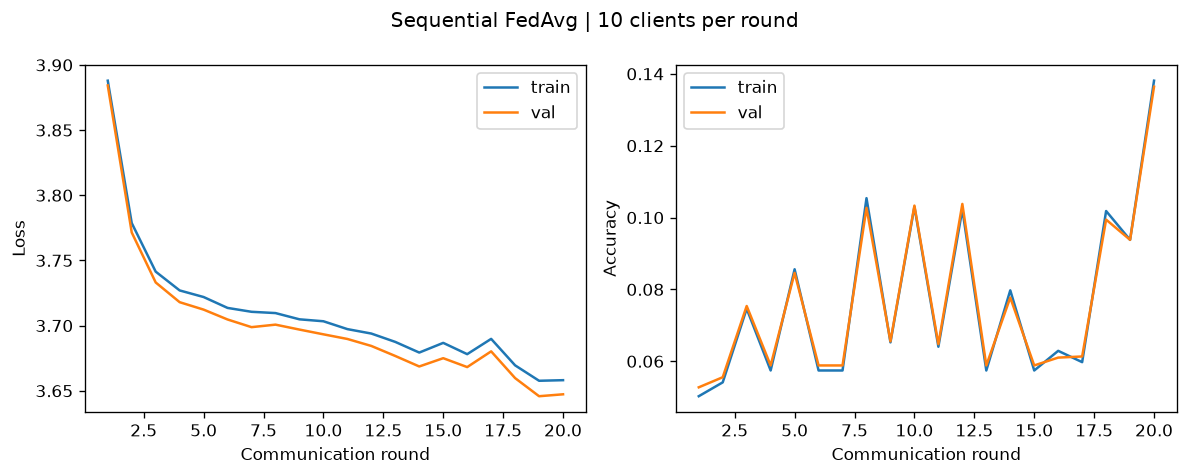

In [8]:
torch.manual_seed(42)
round_rng = np.random.default_rng(42)
global_model = make_model()
history = {"train": [], "val": []}

for round_id in range(1, 21):
    selected = round_rng.choice(len(client_splits), size=10, replace=False)
    fedavg_round(global_model, selected, epochs=3)

    for split in history:
        history[split].append(evaluate_all(global_model, split))

    if round_id == 1 or round_id % 5 == 0:
        val_loss, val_acc = history["val"][-1]
        print(f"Round {round_id:2d}  val loss={val_loss:.3f}  val acc={val_acc:.1%}")

plot_history(history, "Sequential FedAvg | 10 clients per round", "sequential_curves.png")

### Aggregation check

Compare one FedAvg round with the explicit weighted average of two independently trained local models.

In [9]:
start = make_model()
actual = deepcopy(start)

torch.manual_seed(123)
fedavg_round(actual, [0, 1], epochs=1)

torch.manual_seed(123)
local_models = [deepcopy(start), deepcopy(start)]
sizes = []
for i, local in enumerate(local_models):
    x, y = client_splits[i]["train"]
    train_local(local, x, y, epochs=1)
    sizes.append(len(y))

n0, n1 = sizes
w0, w1 = [local.state_dict() for local in local_models]

max_error = 0.0
for name, param in actual.state_dict().items():
    expected = (n0 * w0[name] + n1 * w1[name]) / (n0 + n1)
    torch.testing.assert_close(param, expected, atol=1e-6, rtol=1e-5)
    max_error = max(max_error, (param - expected).abs().max().item())

print(f"Training examples: {sizes} | Maximum parameter error: {max_error:.2e}")

Training examples: [275, 297] | Maximum parameter error: 1.49e-08


### Hyperparameter comparison and held-out evaluation

The four settings use the same starting seed and 50 communication rounds. Select the setting with the highest validation accuracy.

In [10]:
results = {}
best_model = None
best_setting = None

for num_clients in (5, 10):
    for epochs in (1, 3):
        torch.manual_seed(42)
        round_rng = np.random.default_rng(42)
        model = make_model()

        for _ in range(50):
            order = round_rng.permutation(len(client_splits))
            fedavg_round(model, order[:num_clients], epochs=epochs)

        _, train_acc = evaluate_all(model, "train")
        _, val_acc = evaluate_all(model, "val")
        setting = (num_clients, epochs)
        results[setting] = (train_acc, val_acc)
        if best_setting is None or val_acc > results[best_setting][1]:
            best_setting = setting
            best_model = model

        print(f"C={num_clients}%  E={epochs}  "
              f"train={train_acc:.1%}  val={val_acc:.1%}")
print(f"Selected C={best_setting[0] / len(client_splits):.0%}, E={best_setting[1]}")

C=5%  E=1  train=5.4%  val=5.2%
C=5%  E=3  train=11.0%  val=11.0%
C=10%  E=1  train=10.0%  val=9.7%
C=10%  E=3  train=20.0%  val=20.0%
Selected C=10%, E=3


In [11]:
with ZipFile(DATA_ARCHIVE) as archive:
    with archive.open("Assignment3-data/test_data.npy") as file:
        test_data = np.load(file, allow_pickle=True)

x_test = np.asarray(test_data[0]["images"])
y_test = np.asarray(test_data[0]["labels"])
test_loss, test_acc = evaluate(best_model, x_test, y_test)

print(f"Test images: {len(y_test)} | test loss: {test_loss:.3f} | test acc: {test_acc:.1%}")

Test images: 3621 | test loss: 3.427 | test acc: 21.2%


### Per-client comparison with a majority-class baseline

Each point is one client's validation result. Points above the diagonal favor FedAvg.

Clients where FedAvg beats the local majority baseline: 98/100


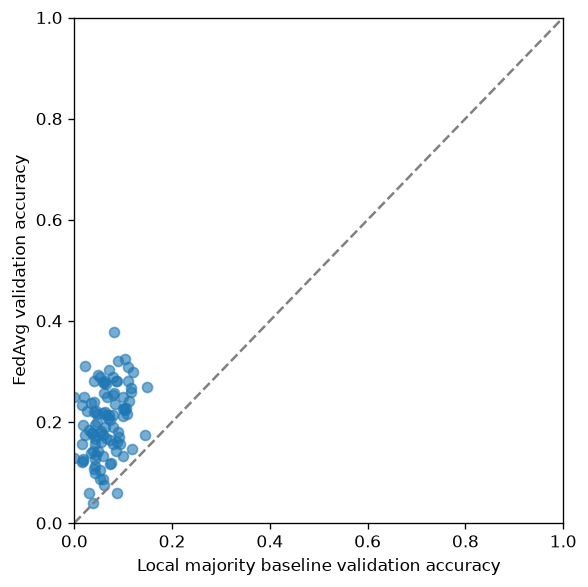

In [12]:
baseline_accs = []
fedavg_accs = []

for client in client_splits:
    _, y_local = client["train"]
    x_check, y_check = client["val"]

    most_common = np.bincount(y_local, minlength=62).argmax()
    baseline_accs.append(np.mean(y_check == most_common))
    fedavg_accs.append(evaluate(best_model, x_check, y_check)[1])

baseline_accs = np.array(baseline_accs)
fedavg_accs = np.array(fedavg_accs)
wins = np.count_nonzero(fedavg_accs > baseline_accs + 1e-7)
print(f"Clients where FedAvg beats the local majority baseline: {wins}/{len(client_splits)}")

plt.figure(figsize=(5, 5))
plt.scatter(baseline_accs, fedavg_accs, alpha=0.6)
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("Local majority baseline validation accuracy")
plt.ylabel("FedAvg validation accuracy")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "client_baseline.png", dpi=180)
plt.show()

## 4. Parallel FedAvg with Ray Core

Each round selects four clients. Each Actor reserves one CPU and is released after its batch finishes.

In [13]:
import ray

if not ray.is_initialized():
    ray.init(include_dashboard=False, num_gpus=0)

print("Ray CPU:", ray.cluster_resources().get("CPU", 0))

@ray.remote(num_cpus=1)
class ClientActor:
    def fit(self, state, x, y, epochs, seed):
        torch.set_num_threads(1)
        torch.manual_seed(seed)
        local = make_model("cpu")
        local.load_state_dict(state)
        train_local(local, x, y, epochs=epochs)
        return len(y), local.state_dict()

def ray_round(model, selected, epochs, round_id):
    state = {name: param.cpu() for name, param in model.state_dict().items()}

    cpu_slots = int(ray.cluster_resources().get("CPU", 0))
    if cpu_slots < 1:
        raise RuntimeError("Ray requires at least one CPU")

    updates = []
    for start in range(0, len(selected), cpu_slots):
        actors = []
        try:
            jobs = []
            for i in selected[start:start + cpu_slots]:
                x, y = client_splits[i]["train"]
                actor = ClientActor.remote()
                actors.append(actor)
                jobs.append(actor.fit.remote(
                    state, x, y, epochs, 1000 * round_id + int(i)
                ))
            updates.extend(ray.get(jobs))
        finally:
            for actor in actors:
                ray.kill(actor)

    aggregate_updates(model, updates)


def run_ray(rounds):
    torch.manual_seed(42)
    rng = np.random.default_rng(42)
    ray_model = make_model()
    ray_history = {"train": [], "val": []}

    for r in range(1, rounds + 1):
        selected = rng.choice(len(client_splits), size=4, replace=False)
        ray_round(ray_model, selected, epochs=3, round_id=r)
        for split in ray_history:
            ray_history[split].append(evaluate_all(ray_model, split))
        print(f"Round {r:2d} | val acc={ray_history['val'][-1][1]:.1%}")

    return ray_model, ray_history

Ray CPU: 10.0


Round  1 | val acc=5.1%
Round  2 | val acc=5.1%
Round  3 | val acc=5.1%
Round  4 | val acc=5.7%
Round  5 | val acc=3.3%
Round  6 | val acc=4.9%
Round  7 | val acc=5.1%
Round  8 | val acc=10.5%
Round  9 | val acc=6.3%
Round 10 | val acc=8.4%
Round 11 | val acc=5.1%
Round 12 | val acc=5.9%
Round 13 | val acc=11.3%
Round 14 | val acc=10.4%
Round 15 | val acc=5.9%
Round 16 | val acc=5.9%
Round 17 | val acc=5.2%
Round 18 | val acc=8.5%
Round 19 | val acc=6.5%
Round 20 | val acc=6.8%
Ray final validation accuracy: 6.8%
Ray test accuracy: 6.7%


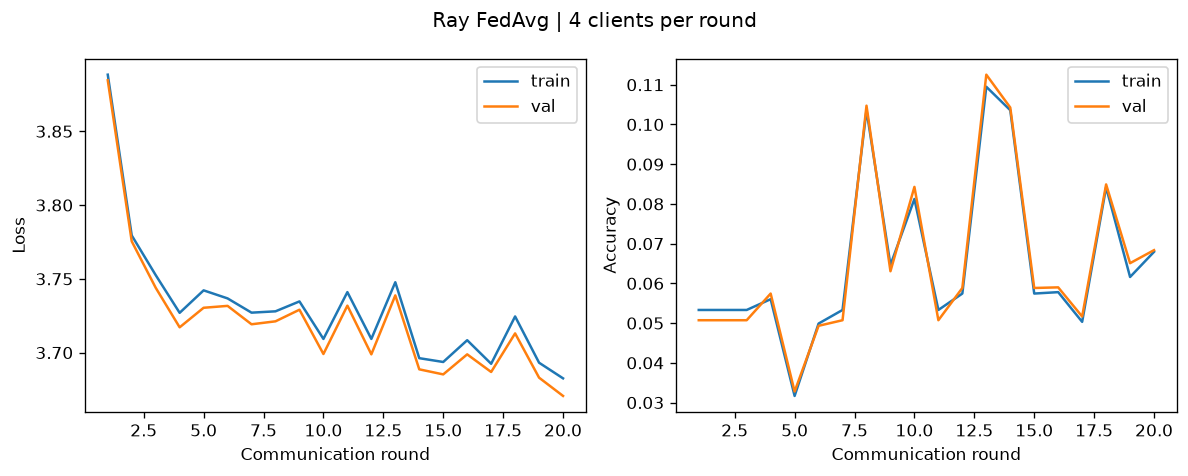

In [14]:
ray_model, ray_history = run_ray(20)
_, ray_val_acc = ray_history["val"][-1]
_, ray_test_acc = evaluate(ray_model, x_test, y_test)
print(f"Ray final validation accuracy: {ray_val_acc:.1%}")
print(f"Ray test accuracy: {ray_test_acc:.1%}")
plot_history(ray_history, "Ray FedAvg | 4 clients per round", "ray_curves.png")

## 5. Laplace input perturbation

Add independent zero-centered Laplace noise to each pixel of each client's training images. Sample the perturbed training set once per scale and reuse it for all 50 rounds. Keep the validation and held-out test images clean, and compute the training accuracy on the clean training split for a common evaluation input across scales.

Use 10 clients per round and 3 local epochs for every scale. Reuse the same initialization and client sampling seeds. Include \(b=0\) as the no-noise control. Noise scale is measured in units of the original pixel values.

In [15]:
def perturb_training_images(scale, seed=123):
    if not np.isfinite(scale) or scale < 0:
        raise ValueError("Laplace scale must be finite and nonnegative")
    rng = np.random.default_rng(seed)
    perturbed = []
    for client in client_splits:
        x, _ = client["train"]
        noise = rng.laplace(loc=0.0, scale=scale, size=x.shape).astype(x.dtype)
        perturbed.append(x + noise)
    return perturbed


noise_models = {}
noise_results = {}

for b in (0.0, 0.1, 0.3, 0.6):
    torch.manual_seed(42)
    round_rng = np.random.default_rng(42)
    noisy_model = make_model()
    noisy_images = perturb_training_images(b) if b > 0 else None
    train_curve, val_curve = [], []

    for _ in range(50):
        selected = round_rng.permutation(len(client_splits))[:10]
        fedavg_round(noisy_model, selected, epochs=3, train_images=noisy_images)
        train_curve.append(evaluate_all(noisy_model, "train")[1])
        val_curve.append(evaluate_all(noisy_model, "val")[1])

    _, noise_test_acc = evaluate(noisy_model, x_test, y_test)
    noise_models[b] = noisy_model
    noise_results[b] = (train_curve, val_curve, noise_test_acc)
    print(f"b={b:.1f} | train={train_curve[-1]:.1%} | "
          f"val={val_curve[-1]:.1%} | test={noise_test_acc:.1%}")

b=0.0 | train=20.0% | val=20.0% | test=21.2%
b=0.1 | train=19.7% | val=19.8% | test=20.8%
b=0.3 | train=21.9% | val=22.3% | test=22.9%
b=0.6 | train=21.2% | val=21.2% | test=22.5%


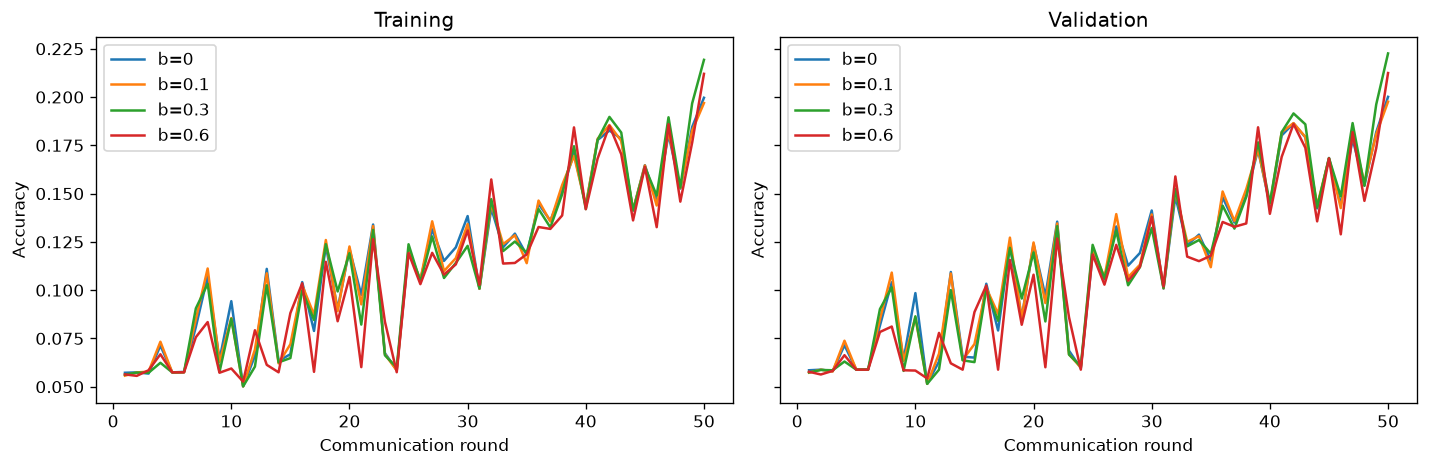

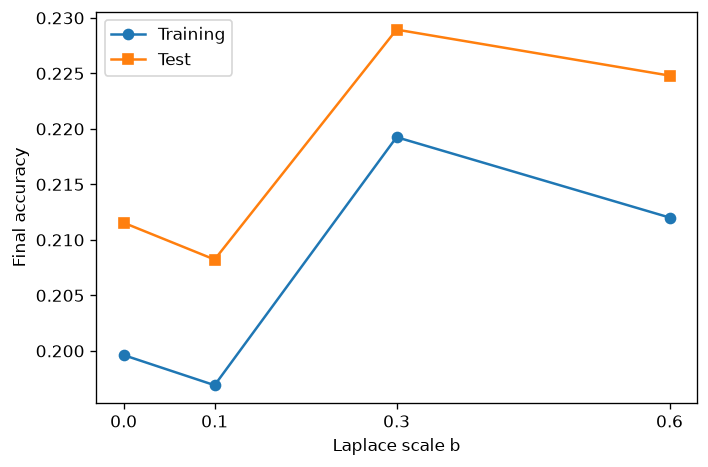

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for b, (train_curve, val_curve, _) in noise_results.items():
    rounds = range(1, len(train_curve) + 1)
    axes[0].plot(rounds, train_curve, label=f"b={b:g}")
    axes[1].plot(rounds, val_curve, label=f"b={b:g}")

for ax, title in zip(axes, ("Training", "Validation")):
    ax.set_title(title)
    ax.set_xlabel("Communication round")
    ax.set_ylabel("Accuracy")
    ax.legend()

fig.tight_layout()
plt.savefig(FIGURE_DIR / "noise_round_curves.png", dpi=180)
plt.show()

scales = list(noise_results)
plt.figure(figsize=(6, 4))
plt.plot(scales, [noise_results[b][0][-1] for b in scales], "o-", label="Training")
plt.plot(scales, [noise_results[b][2] for b in scales], "s-", label="Test")
plt.xlabel("Laplace scale b")
plt.ylabel("Final accuracy")
plt.xticks(scales)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "noise_final_accuracy.png", dpi=180)
plt.show()

### Noise checks and per-client effect

The zero-noise run should reproduce the matched sequential setting. For positive scale, the mean absolute perturbation should approach the requested scale and its signed mean should approach zero. The per-client plot compares validation accuracy at the largest tested scale against the control, using the same validation samples for both models.

Zero-noise control matches sequential FedAvg: val=20.0%
Noise check | b=0.3 | mean=0.0011 | mean absolute perturbation=0.2994
Median per-client change: +1.37 percentage points


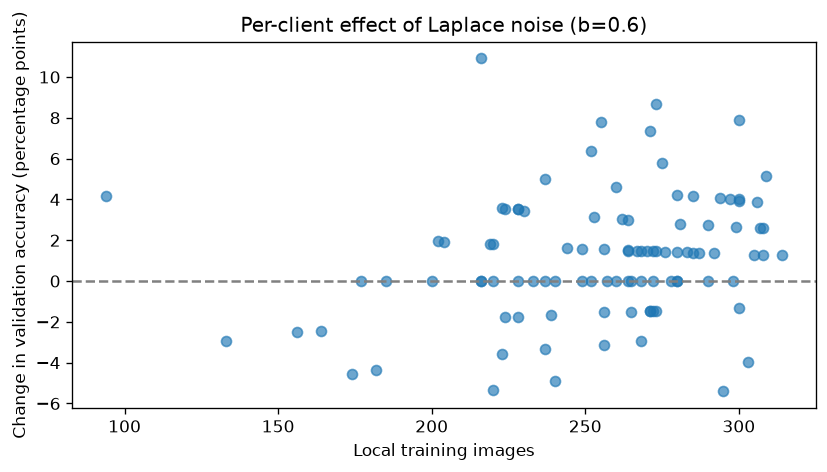

In [17]:
control_train, control_val, _ = noise_results[0.0]
expected_train, expected_val = results[10, 3]
np.testing.assert_allclose(
    [control_train[-1], control_val[-1]], [expected_train, expected_val],
    atol=1e-6, rtol=0,
)
print(f"Zero-noise control matches sequential FedAvg: val={control_val[-1]:.1%}")

original_images, _ = client_splits[0]["train"]
checked_scale = 0.3
perturbed_images = perturb_training_images(checked_scale)[0]
observed_noise = perturbed_images - original_images
signed_mean = float(observed_noise.mean())
observed_scale = float(np.abs(observed_noise).mean())
assert abs(signed_mean) < 0.02 * checked_scale
assert abs(observed_scale - checked_scale) < 0.02 * checked_scale
print(f"Noise check | b={checked_scale:g} | mean={signed_mean:.4f} | "
      f"mean absolute perturbation={observed_scale:.4f}")

largest_scale = max(noise_results)
client_sizes, accuracy_changes = [], []
for client in client_splits:
    _, y_train = client["train"]
    x_val, y_val = client["val"]
    control_acc = evaluate(noise_models[0.0], x_val, y_val)[1]
    perturbed_acc = evaluate(noise_models[largest_scale], x_val, y_val)[1]
    client_sizes.append(len(y_train))
    accuracy_changes.append(100 * (perturbed_acc - control_acc))

plt.figure(figsize=(7, 4))
plt.scatter(client_sizes, accuracy_changes, alpha=0.65)
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Local training images")
plt.ylabel("Change in validation accuracy (percentage points)")
plt.title(f"Per-client effect of Laplace noise (b={largest_scale:g})")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "noise_client_effect.png", dpi=180)
plt.show()
print(f"Median per-client change: {np.median(accuracy_changes):+.2f} percentage points")

### Results and choice of scale

| Laplace scale | Final training accuracy | Final validation accuracy | Test accuracy |
| --- | ---: | ---: | ---: |
| 0.0 | 20.0% | 20.0% | 21.2% |
| 0.1 | 19.7% | 19.8% | 20.8% |
| 0.3 | 21.9% | 22.3% | 22.9% |
| 0.6 | 21.2% | 21.2% | 22.5% |

In this run, accuracy dipped slightly at $b=0.1$, peaked at $b=0.3$, and then dropped at $b=0.6$. I would use $b=0.3$ among the tested scales because it perturbs the inputs and gives the highest observed validation accuracy. The larger scale $b=0.6$ adds stronger perturbation at a cost of 1.1 percentage points of validation accuracy relative to $b=0.3$. This comparison uses one seed. Quantifying a formal privacy guarantee would require defining the protected unit and bounding the sensitivity of the release.

## 6. Validation experiments

Run this section after Sections 1-5. The experiments compare algorithmic limits with explicit predictions, keep serial and Ray work matched, and repeat the perturbation experiment across training seeds. The held-out test data stay outside all parameter updates. Every check prints a quantitative result and raises an assertion error if its stated prediction fails.

In [18]:
# Data heterogeneity and split isolation.
client_sizes_all = np.array([len(client["labels"]) for client in train_data])
train_sizes = np.array([len(client["train"][1]) for client in client_splits])
val_sizes = np.array([len(client["val"][1]) for client in client_splits])
split_overlaps = [len(np.intersect1d(c["train_indices"], c["val_indices"])) for c in client_splits]
assert sum(split_overlaps) == 0
assert np.array_equal(train_sizes + val_sizes, client_sizes_all)
class_coverage = (client_counts > 0).sum(axis=1)
print(f"Total local samples: {client_sizes_all.sum()}; train: {train_sizes.sum()}; validation: {val_sizes.sum()}")
print(f"Client sample counts: min={client_sizes_all.min()}, median={np.median(client_sizes_all):.0f}, max={client_sizes_all.max()}")
print(f"Classes per client: min={class_coverage.min()}, median={np.median(class_coverage):.0f}, max={class_coverage.max()}")
print(f"Train/validation overlap: {sum(split_overlaps)} indices across 100 clients")

# With one client, FedAvg must equal local training from the same initialization.
torch.manual_seed(77)
single_fed = make_model()
single_local = deepcopy(single_fed)
x_single, y_single = client_splits[0]["train"]
torch.manual_seed(78)
fedavg_round(single_fed, [0], epochs=1)
torch.manual_seed(78)
train_local(single_local, x_single, y_single, epochs=1)
single_error = max((p - single_local.state_dict()[k]).abs().max().item() for k, p in single_fed.state_dict().items())
assert single_error < 1e-6
print(f"Single-client FedAvg versus local training: maximum parameter error={single_error:.2e}")

# At zero learning rate, local updates and their average must preserve the model.
zero_lr_model = make_model()
zero_lr_before = deepcopy(zero_lr_model.state_dict())
fedavg_round(zero_lr_model, [0, 1], epochs=1, lr=0)
zero_lr_error = max((p - zero_lr_before[k]).abs().max().item() for k, p in zero_lr_model.state_dict().items())
assert zero_lr_error < 1e-6
print(f"Zero learning rate: maximum parameter change={zero_lr_error:.2e}")

# Small real-data overfitting checks whether the model can fit a controlled task.
tiny_x, tiny_y = x_single[:16], y_single[:16]
torch.manual_seed(79)
tiny_model = make_model("cpu")
tiny_before = evaluate(tiny_model, tiny_x, tiny_y)
train_local(tiny_model, tiny_x, tiny_y, epochs=2000, lr=0.01)
tiny_after = evaluate(tiny_model, tiny_x, tiny_y)
assert tiny_after[0] < tiny_before[0]
assert tiny_after[1] >= 0.95
print(f"16-image fit: loss {tiny_before[0]:.3f} -> {tiny_after[0]:.3f}; accuracy {tiny_before[1]:.1%} -> {tiny_after[1]:.1%}")

Total local samples: 31825; train: 25418; validation: 6407
Client sample counts: min=118, median=331, max=393
Classes per client: min=37, median=56, max=61
Train/validation overlap: 0 indices across 100 clients
Single-client FedAvg versus local training: maximum parameter error=0.00e+00
Zero learning rate: maximum parameter change=3.73e-09
16-image fit: loss 4.165 -> 0.137; accuracy 0.0% -> 100.0%


### Matched serial and Ray updates

Use the same CPU model, selected clients, model initialization, and per-client seeds for three rounds. Creating each local model before loading the starting state reproduces the Actor's random-number consumption. Compare all parameters after every round. Time only the update computation, including Actor creation and cleanup.

In [19]:
torch.manual_seed(81)
serial_check = make_model("cpu")
parallel_check = deepcopy(serial_check)
match_rng = np.random.default_rng(81)
matched_errors = []
serial_seconds = parallel_seconds = 0.0
previous_threads = torch.get_num_threads()
torch.set_num_threads(1)
try:
    for r in range(1, 4):
        selected = match_rng.choice(len(client_splits), size=4, replace=False)
        state = deepcopy(serial_check.state_dict())
        start_time = time.perf_counter()
        updates = []
        for i in selected:
            torch.manual_seed(1000 * r + int(i))
            local = make_model("cpu")
            local.load_state_dict(state)
            x, y = client_splits[i]["train"]
            train_local(local, x, y, epochs=3)
            updates.append((len(y), local.state_dict()))
        aggregate_updates(serial_check, updates)
        serial_seconds += time.perf_counter() - start_time

        start_time = time.perf_counter()
        ray_round(parallel_check, selected, epochs=3, round_id=r)
        parallel_seconds += time.perf_counter() - start_time
        error = max((p - parallel_check.state_dict()[k]).abs().max().item() for k, p in serial_check.state_dict().items())
        matched_errors.append(error)
        assert error < 1e-6
        print(f"Matched round {r}: maximum serial/Ray parameter error={error:.2e}")
finally:
    torch.set_num_threads(previous_threads)
print(f"Matched 3-round update time: serial={serial_seconds:.3f}s; Ray={parallel_seconds:.3f}s")

Matched round 1: maximum serial/Ray parameter error=0.00e+00
Matched round 2: maximum serial/Ray parameter error=0.00e+00
Matched round 3: maximum serial/Ray parameter error=0.00e+00
Matched 3-round update time: serial=0.078s; Ray=4.688s


### Noise robustness and extreme perturbation

Repeat every main scale with training and client-sampling seeds 43 and 44, with noise seeds 124 and 125. Keep the original 80/20 split fixed. Report mean and sample standard deviation over seeds 42, 43, and 44. These repetitions use validation accuracy. Compare the high-noise stress case b=3 against the same-seed control to measure sensitivity when perturbations dominate the [0, 1] pixel range.

Seed=43 b=0: validation accuracy=19.0%
Seed=43 b=0.1: validation accuracy=19.2%
Seed=43 b=0.3: validation accuracy=19.6%
Seed=43 b=0.6: validation accuracy=18.2%
Seed=44 b=0: validation accuracy=15.3%
Seed=44 b=0.1: validation accuracy=15.7%
Seed=44 b=0.3: validation accuracy=16.9%
Seed=44 b=0.6: validation accuracy=16.7%
b=0: validation mean=18.1%, SD=2.5%
b=0.1: validation mean=18.2%, SD=2.2%
b=0.3: validation mean=19.6%, SD=2.7%
b=0.6: validation mean=18.7%, SD=2.3%
Stress b=3: validation accuracy=13.6%; perturbed pixels outside [0,1]=85.8%
Negative scale rejected; b=0 preserves every pixel exactly


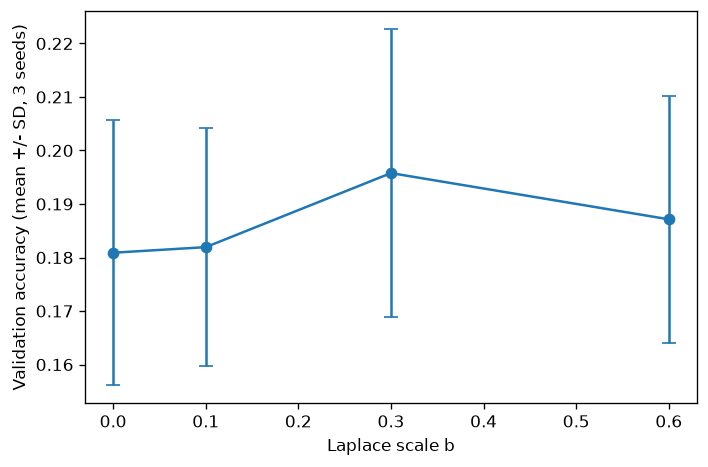

In [20]:
seed_validation = {b: [values[1][-1]] for b, values in noise_results.items()}
for seed in (43, 44):
    for b in noise_results:
        torch.manual_seed(seed)
        seed_model = make_model()
        seed_rng = np.random.default_rng(seed)
        seed_images = perturb_training_images(b, seed=seed + 81) if b > 0 else None
        for _ in range(50):
            selected = seed_rng.permutation(len(client_splits))[:10]
            fedavg_round(seed_model, selected, epochs=3, train_images=seed_images)
        seed_acc = evaluate_all(seed_model, "val")[1]
        seed_validation[b].append(seed_acc)
        print(f"Seed={seed} b={b:g}: validation accuracy={seed_acc:.1%}")

for b, values in seed_validation.items():
    print(f"b={b:g}: validation mean={np.mean(values):.1%}, SD={np.std(values, ddof=1):.1%}")

plt.figure(figsize=(6, 4))
plt.errorbar(list(seed_validation), [np.mean(v) for v in seed_validation.values()],
             yerr=[np.std(v, ddof=1) for v in seed_validation.values()], fmt="o-", capsize=4)
plt.xlabel("Laplace scale b")
plt.ylabel("Validation accuracy (mean +/- SD, 3 seeds)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "noise_seed_robustness.png", dpi=180)
plt.show()

stress_scale = 3.0
stress_images = perturb_training_images(stress_scale)
torch.manual_seed(42)
stress_model = make_model()
stress_rng = np.random.default_rng(42)
for _ in range(50):
    selected = stress_rng.permutation(len(client_splits))[:10]
    fedavg_round(stress_model, selected, epochs=3, train_images=stress_images)
stress_val_acc = evaluate_all(stress_model, "val")[1]
outside_fraction = sum(np.count_nonzero((x < 0) | (x > 1)) for x in stress_images) / sum(x.size for x in stress_images)
print(f"Stress b=3: validation accuracy={stress_val_acc:.1%}; perturbed pixels outside [0,1]={outside_fraction:.1%}")

# Zero scale preserves the exact inputs; invalid scales fail explicitly.
zero_images = perturb_training_images(0)
assert all(np.array_equal(x, c["train"][0]) for x, c in zip(zero_images, client_splits))
try:
    perturb_training_images(-0.1)
except ValueError:
    print("Negative scale rejected; b=0 preserves every pixel exactly")
else:
    raise AssertionError("Negative noise scale must fail")

## 7. Results export and further experiments

The next cell writes the numerical evidence used by the PDF report. The figures are exported as the preceding cells run. Given three additional months, repeat the full comparison across more seeds and independent client splits, tune learning rate and communication budget using validation data, test client dropout and strongly imbalanced participation, and evaluate privacy after explicitly defining adjacency, sensitivity, and the released information. The current seed-level results quantify the uncertainty in the observed noise trend.

In [21]:
report_results = {
    "environment": {"python": platform.python_version(), "torch": torch.__version__, "numpy": np.__version__, "ray": ray.__version__, "device": str(device), "ray_cpus": ray.cluster_resources().get("CPU", 0)},
    "data": {"clients": len(client_splits), "total": int(client_sizes_all.sum()), "train": int(train_sizes.sum()), "validation": int(val_sizes.sum()), "test": len(y_test), "sizes": client_sizes_all.tolist(), "coverage": class_coverage.tolist(), "class_counts": overall_counts.tolist(), "five_client_counts": client_counts[:5].tolist(), "split_overlap": sum(split_overlaps)},
    "sequential": {"history": history, "grid": [{"clients": k[0], "epochs": k[1], "train": v[0], "validation": v[1]} for k, v in results.items()], "test": test_acc, "test_loss": test_loss, "baseline_wins": int(wins), "aggregation_error": max_error},
    "ray": {"history": ray_history, "test": ray_test_acc},
    "noise": {str(b): {"train_curve": v[0], "validation_curve": v[1], "test": v[2], "seed_validation": seed_validation[b]} for b, v in noise_results.items()},
    "validation": {"single_client_error": single_error, "zero_lr_error": zero_lr_error, "tiny_before": tiny_before, "tiny_after": tiny_after, "matched_errors": matched_errors, "serial_seconds": serial_seconds, "ray_seconds": parallel_seconds, "noise_mean": signed_mean, "noise_abs_mean": observed_scale, "median_client_change": float(np.median(accuracy_changes)), "stress_validation": stress_val_acc, "stress_outside_fraction": outside_fraction}
}
Path("experiment_results.json").write_text(json.dumps(report_results, indent=2) + "\n")
print("Saved experiment_results.json and figures/")
ray.shutdown()

Saved experiment_results.json and figures/
